In [7]:
import torch
from torchvision.datasets import OxfordIIITPet
from torchvision.transforms import v2
from torch.utils.data import DataLoader
import wandb
torch.backends.cudnn.benchmark = True

In [8]:
image_transform = v2.Compose([
    v2.Resize((224, 224)),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
])

def mask_transform(mask):
    mask = v2.functional.resize(
        mask,
        (224,224),
        interpolation=v2.InterpolationMode.NEAREST
    )
    mask = v2.functional.pil_to_tensor(mask).long()
    mask = mask.squeeze(0) - 1      # now classes become 0,1,2
    return mask

dataset = OxfordIIITPet(
    root="data",
    split="trainval",
    target_types="segmentation",
    transform=image_transform,
    target_transform=mask_transform,
    download=True,
)

loader = DataLoader(dataset, batch_size=32, shuffle=True)

images, masks = next(iter(loader))

print(images.shape)   # [32, 3, 224, 224]
print(masks.shape)    # [32, 1, 224, 224]
print(masks.dtype)

torch.Size([32, 3, 224, 224])
torch.Size([32, 224, 224])
torch.int64


In [9]:
from torch.utils.data import random_split

train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size

train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

train_loader = DataLoader(train_dataset, batch_size = 64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size = 64, shuffle=False)

In [15]:
import torch.nn as nn
import torch.nn.functional as F

num_classes = 3
class UNet(nn.Module):

    class Encoder(nn.Module):

        def __init__(self,InputDepth: int,OutputDepth: int, FilterSize: int, stride = 1) -> None:
            super().__init__()
            self.conv1 = nn.Conv2d(InputDepth,OutputDepth,FilterSize,stride, padding= 1)
            self.conv2 = nn.Conv2d(OutputDepth,OutputDepth,FilterSize, padding= 1)
        
        def forward(self,x):
            x = F.relu(self.conv1(x))
            x = F.relu(self.conv2(x))
            return x
        
    class Decoder(nn.Module):
        def __init__(self,InputDepth: int) -> None:
            super().__init__()
            self.up1 = nn.ConvTranspose2d(InputDepth,InputDepth // 2,2,stride=2)
            self.conv = UNet.Encoder(InputDepth,InputDepth // 2,3)

        def forward(self, x, skip):
            x = self.up1(x)
            x = torch.cat([skip, x], dim=1)
            x = self.conv(x)
            return x
        
    def __init__(self) -> None:
        super().__init__()
        self.pool = nn.MaxPool2d(2,2)
        self.encoder1 = self.Encoder(3,64,3)
        self.encoder2 = self.Encoder(64,128,3)
        self.encoder3 = self.Encoder(128,256,3)
        self.encoder4 = self.Encoder(256,512,3)
        self.bottleneck = self.Encoder(512,1024,3)
        self.decoder1 = self.Decoder(1024)
        self.decoder2 = self.Decoder(512)
        self.decoder3 = self.Decoder(256,)
        self.decoder4 = self.Decoder(128)
        self.final = nn.Conv2d(64, num_classes, kernel_size=1)


    def forward(self,x):
        stack = []
        x = self.encoder1(x)
        stack.append(x)
        x = self.pool(x)
        x = self.encoder2(x)
        stack.append(x)
        x = self.pool(x)
        x = self.encoder3(x)
        stack.append(x)
        x = self.pool(x)
        x = self.encoder4(x)
        stack.append(x)
        x = self.pool(x)
        x = self.bottleneck(x)
        x = self.decoder1(x,stack.pop())
        x = self.decoder2(x,stack.pop())
        x = self.decoder3(x,stack.pop())
        x = self.decoder4(x,stack.pop())
        return self.final(x)
    
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = UNet()
model = model.to(device)

In [16]:
def mean_iou(pred, target, num_classes):

    pred = pred.argmax(1)

    ious = []

    for cls in range(num_classes):

        pred_cls = pred == cls
        target_cls = target == cls

        intersection = (pred_cls & target_cls).sum().float()

        union = (pred_cls | target_cls).sum().float()

        if union == 0:
            continue

        ious.append(intersection / union)

    return torch.mean(torch.stack(ious))

In [17]:
import torch.optim as optim

ce = nn.CrossEntropyLoss()

class DiceLoss(nn.Module):

    def forward(self, pred, target, smooth=1):

        pred = F.softmax(pred, dim=1)
        target = F.one_hot(target,pred.shape[1]).permute(0,3,1,2).float()

        intersection = (pred * target).sum((2,3))

        union = pred.sum((2,3)) + target.sum((2,3))

        dice = (2*intersection + smooth)/(union + smooth)

        return 1 - dice.mean()
    
dice = DiceLoss()

optimizer = optim.AdamW(model.parameters(),lr=1e-3)
scaler = torch.amp.GradScaler("cuda")

In [18]:
for epoch in range(15):

    model.train()

    running_loss = 0.0
    for images,masks in train_loader:
        
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)
        masks = masks.squeeze(1)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            output = model(images)
            loss = ce(output, masks) + dice(output, masks)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        

        running_loss += loss.item()

    print(f'[{epoch + 1}] loss: {running_loss / len(train_loader):.3f}')



[1] loss: 2.683
[2] loss: 1.585
[3] loss: 1.529
[4] loss: 1.316
[5] loss: 1.251
[6] loss: 1.214
[7] loss: 1.180
[8] loss: 1.142
[9] loss: 1.117
[10] loss: 1.035
[11] loss: 0.975
[12] loss: 0.942
[13] loss: 0.884
[14] loss: 0.817
[15] loss: 0.768


In [ ]:
ious = []
# since we're not training, we don't need to calculate the gradients for our outputs
with torch.inference_mode():
    for data in val_loader:
        images, labels = data
        images = images.to(device)
        labels = labels.to(device)
        # calculate outputs by running images through the network
        outputs = model(images)
        # the class with the highest energy is what we choose as prediction
        labels = labels.squeeze(1)

        ious.append(mean_iou(outputs, labels, 3))

print(torch.mean(torch.stack(ious)))

tensor(0.6064, device='cuda:0')


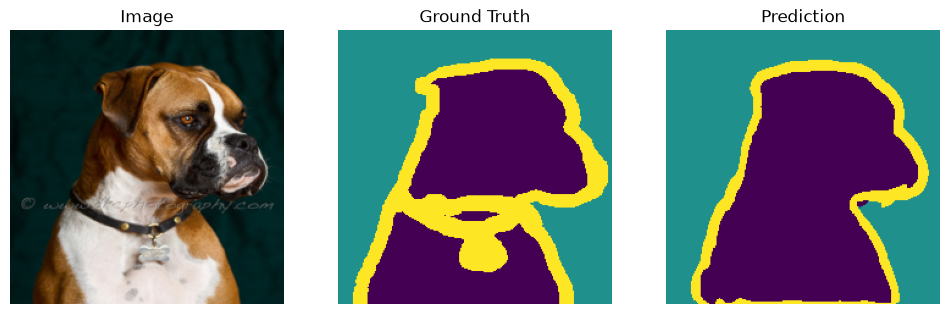

In [21]:
import matplotlib.pyplot as plt
pred = outputs.argmax(1)
images = images.cpu()
labels = labels.cpu()
pred = pred.cpu()
image = images[0].permute(1,2,0)

idx = 0

image = images[idx].permute(1,2,0)
gt = labels[idx]
prediction = pred[idx]

plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.imshow(image)
plt.title("Image")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(gt)
plt.title("Ground Truth")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(prediction)
plt.title("Prediction")
plt.axis("off")

plt.show()

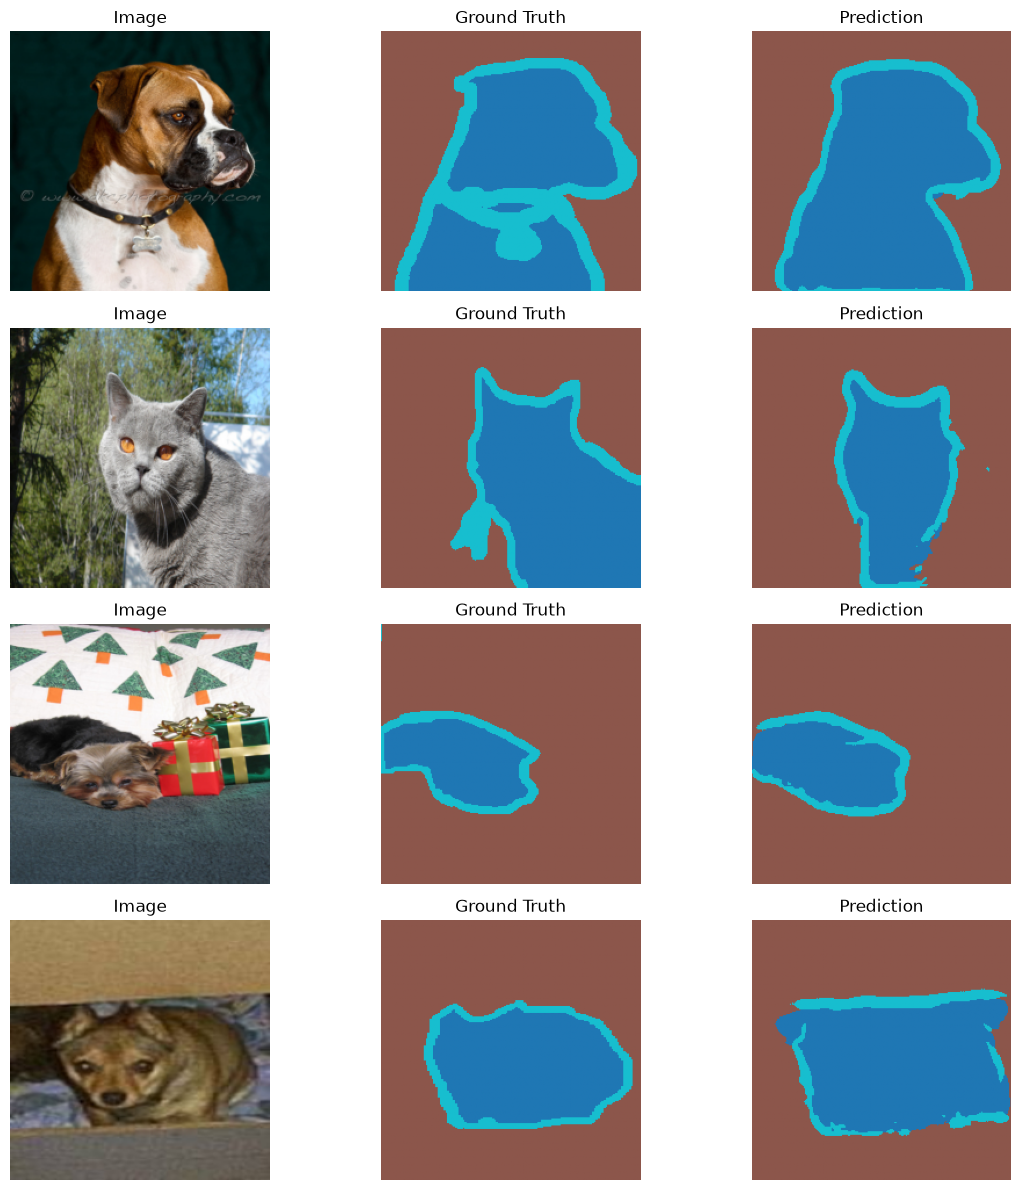

In [23]:
n = 4

plt.figure(figsize=(12,3*n))

for i in range(n):

    image = images[i].permute(1,2,0)
    gt = labels[i]
    pr = pred[i]

    plt.subplot(n,3,3*i+1)
    plt.imshow(image)
    plt.axis("off")
    plt.title("Image")

    plt.subplot(n,3,3*i+2)
    plt.imshow(gt, cmap="tab10")
    plt.axis("off")
    plt.title("Ground Truth")

    plt.subplot(n,3,3*i+3)
    plt.imshow(pr, cmap="tab10")
    plt.axis("off")
    plt.title("Prediction")

plt.tight_layout()
plt.show()